# Exploratory Data Analysis

We explore the structure of the data, visualize image samples with the corresponding segmentation masks.

In [14]:
import h5py
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

from common.config import (
    MAT_PATH,
    FIGS_DIR,
    TARGET_CLASS_NAMES,
    VALIDATION_FRACTION,
    TEST_FRACTION,
    RANDOM_STATE,
)
from common.utils import NYUDepthV2, binary_target_mask, make_data_splits

FIGS_DIR.mkdir(parents=True, exist_ok=True)

PLOT_N_SAMPLES = 10
SAVE_FIG = True

## Overview

In [ ]:
nyu = h5py.File(MAT_PATH, "r")
list(nyu.keys())

['#refs#',
 '#subsystem#',
 'accelData',
 'depths',
 'images',
 'instances',
 'labels',
 'names',
 'namesToIds',
 'rawDepthFilenames',
 'rawDepths',
 'rawRgbFilenames',
 'sceneTypes',
 'scenes']

In [16]:
images = nyu["images"]
labels = nyu["labels"]

print("Images shape:", images.shape)
print("Labels shape:", labels.shape)

Images shape: (1449, 3, 640, 480)
Labels shape: (1449, 640, 480)


In [17]:
names_refs = nyu["names"][0]

class_names = []
for ref in names_refs:
    chars = np.asarray(nyu[ref][()]).ravel(order="F")
    name = "".join(chr(int(c)) for c in chars if int(c) != 0)
    class_names.append(name)

print("Number of classes:", len(class_names))
print("First 20 classes:")

for i, name in enumerate(class_names[:20], start=1):
    print(i, name)

print("\nClasses containing 'floor':")
for i, name in enumerate(class_names, start=1):
    if "floor" in name.lower():
        print(i, name)

Number of classes: 894
First 20 classes:
1 book
2 bottle
3 cabinet
4 ceiling
5 chair
6 cone
7 counter
8 dishwasher
9 faucet
10 fire extinguisher
11 floor
12 garbage bin
13 microwave
14 paper towel dispenser
15 paper
16 pot
17 refridgerator
18 stove burner
19 table
20 unknown

Classes containing 'floor':
11 floor
143 floor mat
868 floor trim


In [18]:
# Load the MAT file and inspect its structure
nyu = NYUDepthV2(MAT_PATH)
print(f"Dataset size: {len(nyu)}")
print(f"Number of semantic classes: {len(nyu.class_names)}")
print("First 25 class names:")
print(nyu.class_names[:25])

target_ids = [nyu.class_names.index(target) + 1 for target in TARGET_CLASS_NAMES]
print(f"Binary target classes: {TARGET_CLASS_NAMES!r} (NYU label IDs {target_ids})")

first_image, first_labels = nyu.get_pair(0)
print(f"RGB image shape (dtype): {first_image.shape} ({first_image.dtype})")
print(f"Label map shape (dtype): {first_labels.shape} ({first_labels.dtype})")

Dataset size: 1449
Number of semantic classes: 894
First 25 class names:
['book', 'bottle', 'cabinet', 'ceiling', 'chair', 'cone', 'counter', 'dishwasher', 'faucet', 'fire extinguisher', 'floor', 'garbage bin', 'microwave', 'paper towel dispenser', 'paper', 'pot', 'refridgerator', 'stove burner', 'table', 'unknown', 'wall', 'bowl', 'magnet', 'sink', 'air vent']
Binary target classes: ['floor', 'floor mat', 'floor trim'] (NYU label IDs [11, 143, 868])
RGB image shape (dtype): (480, 640, 3) (uint8)
Label map shape (dtype): (480, 640) (uint16)


In [19]:
# Create train/validation/test image indices
train_indices, val_indices, test_indices = make_data_splits(
    nyu_dataset=nyu,
    validation_fraction=VALIDATION_FRACTION,
    test_fraction=TEST_FRACTION,
    random_state=RANDOM_STATE,
)
print(f"Train images: {len(train_indices)}")
print(f"Validation images: {len(val_indices)}")
print(f"Test images: {len(test_indices)}")

Train images: 1028
Validation images: 206
Test images: 215


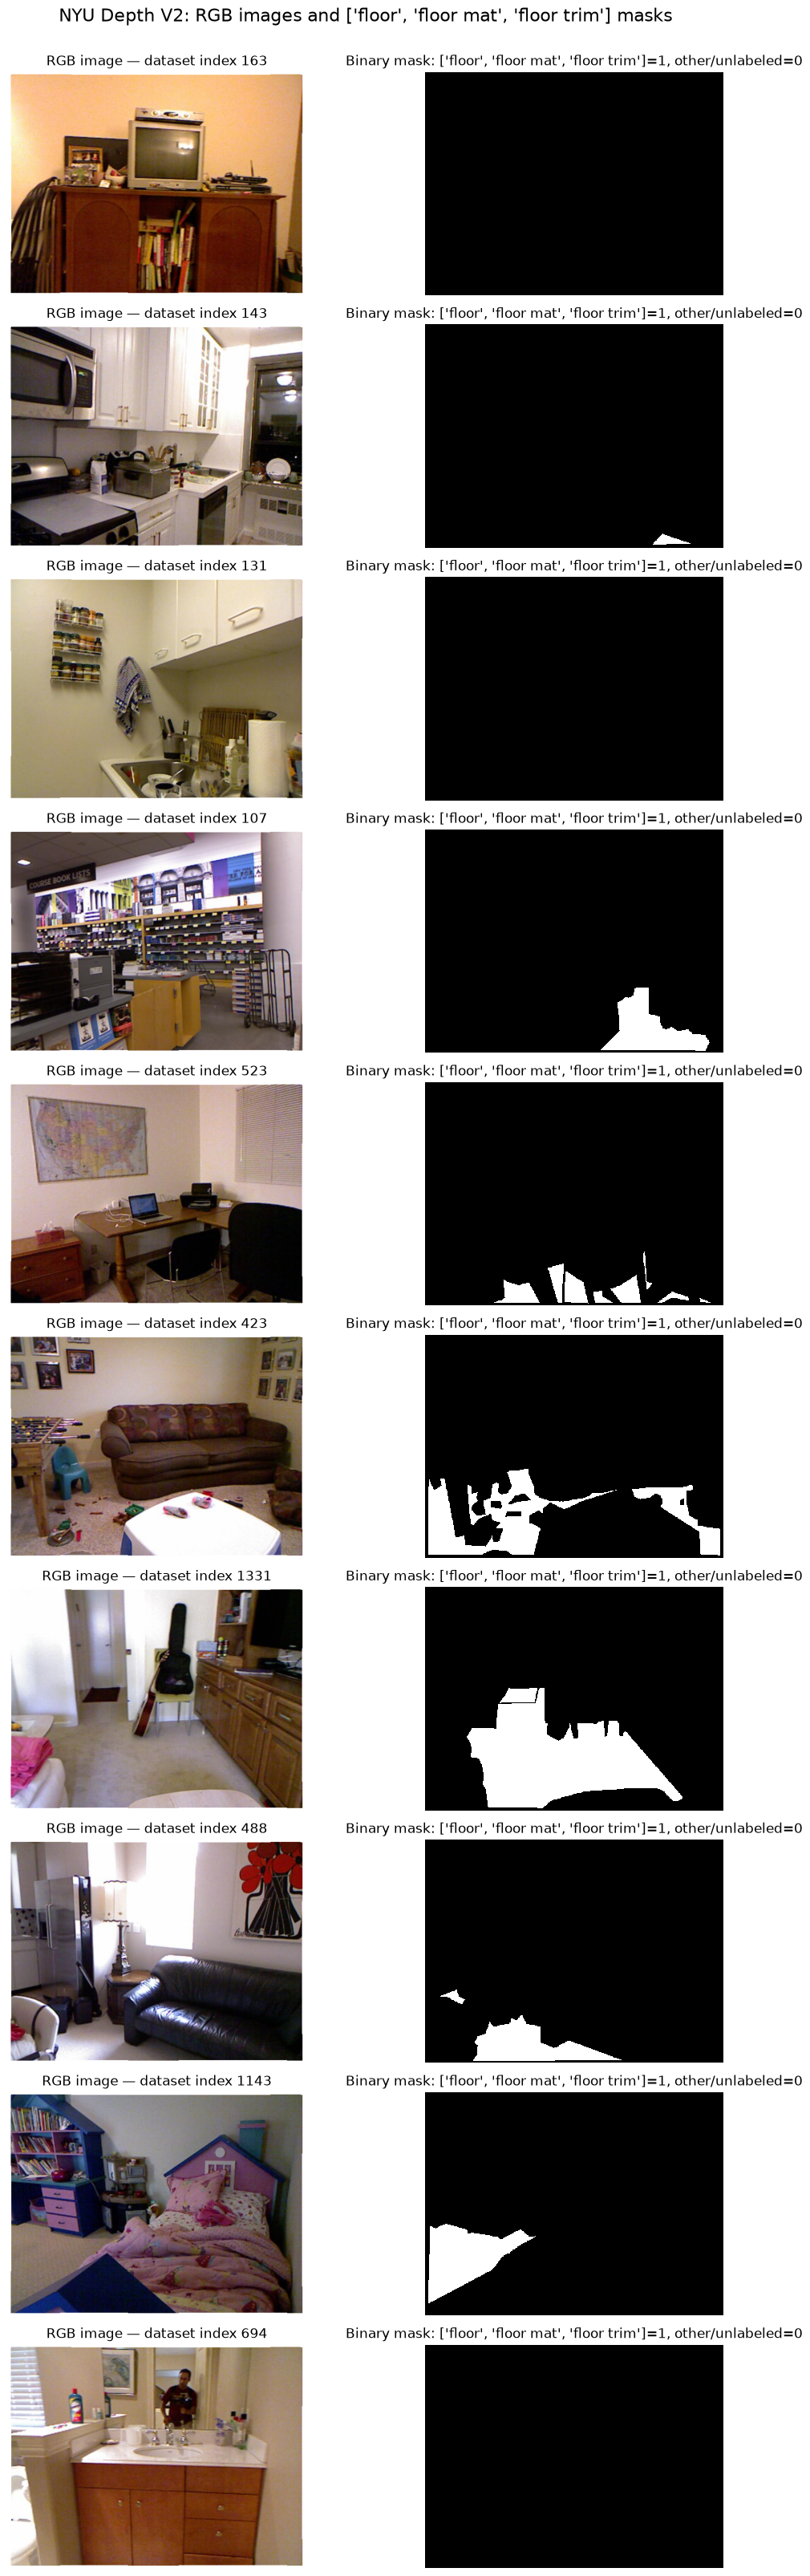

In [20]:
# Visualize 10 RGB images and their corresponding binary masks
rng = np.random.default_rng(RANDOM_STATE)
chosen_images = rng.choice(
    train_indices, size=min(10, len(train_indices)), replace=False
)
fig, axes = plt.subplots(len(chosen_images), 2, figsize=(12, 3.2 * len(chosen_images)))
if len(chosen_images) == 1:
    axes = np.expand_dims(axes, axis=0)

for row, image_index in enumerate(chosen_images):
    rgb, labels = nyu.get_pair(int(image_index))
    mask = binary_target_mask(labels, target_ids)

    axes[row, 0].imshow(rgb)
    axes[row, 0].set_title(f"RGB image — dataset index {image_index}")
    axes[row, 0].axis("off")

    axes[row, 1].imshow(mask, cmap="gray", vmin=0, vmax=1, interpolation="nearest")
    axes[row, 1].set_title(f"Binary mask: {TARGET_CLASS_NAMES}=1, other/unlabeled=0")
    axes[row, 1].axis("off")

fig.suptitle(
    f"NYU Depth V2: RGB images and {TARGET_CLASS_NAMES!r} masks",
    fontsize=16,
    y=1.002,
)
fig.tight_layout()
if SAVE_FIG:
    figure_path = FIGS_DIR / "eda_images_and_masks.png"
    fig.savefig(figure_path, dpi=150, bbox_inches="tight")
plt.show()

In [21]:
# Inspect how common the target classes are in a small sample
positive_fractions = []
valid_fractions = []
for image_index in chosen_images:
    _, labels = nyu.get_pair(int(image_index))
    valid = labels > 0
    valid_count = int(valid.sum())
    valid_fractions.append(valid.mean())
    positive_fractions.append(
        float(np.isin(labels[valid], target_ids).mean()) if valid_count > 0 else 0.0
    )

print(f"Mean fraction of labeled pixels: {np.mean(valid_fractions):.3f}")
print(
    f"Mean target-class fraction among labeled pixels: {np.mean(positive_fractions):.3f}"
)

Mean fraction of labeled pixels: 0.855
Mean target-class fraction among labeled pixels: 0.065


In [12]:
# Close the dataset handle (important for HDF5 files)
nyu.close()